# Naan Stop in New York

DBSCAN on every active restaurant the health department lists as Indian. Run `fetch_week1.py day4` first.

## 1 · Settings

In [6]:
DAY      = 4
PROMPT   = "Clusters"
SLUG     = "clusters-nyc-indian"
NOTEBOOK = "day04_clusters_nyc_indian.ipynb"
TITLE    = "Naan Stop in New York"
CREDITS  = "Restaurants: NYC Department of Health restaurant inspections, active restaurants listed as Indian. Boundary: US Census Bureau."

## 2 · Load

In [7]:
import geopandas as gpd, matplotlib.pyplot as plt, numpy as np, pandas as pd
from sklearn.cluster import DBSCAN
from mapkit import poster, publish
from mapkit.paths import PROCESSED

food = gpd.read_file(PROCESSED / "nyc_indian.geojson")
city = gpd.read_file(PROCESSED / "places_six.geojson").query("city == 'nyc'")

import requests

# Borough shapes with the rivers cut out. Downloads once, then reads the saved file.
f = PROCESSED / "nyc_boroughs.geojson"
if not f.exists():
    official = "https://services5.arcgis.com/GfwWNkhOj9bNBqoJ/arcgis/rest/services/NYC_Borough_Boundary/FeatureServer/0/query"
    backup = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/new-york-city-boroughs.geojson"
    try:
        r = requests.get(official, params={"where": "1=1", "outFields": "*", "outSR": 4326, "f": "geojson"}, timeout=120)
        assert len(r.json()["features"]) == 5
    except Exception:
        print("City Planning download failed, using the backup copy")
        r = requests.get(backup, timeout=120)
    f.write_bytes(r.content)
    (PROCESSED / "nyc_boroughs_source.txt").write_text("official" if "arcgis" in r.url else "backup")
boroughs = gpd.read_file(f)
nj = gpd.read_file(PROCESSED / "ski_states.geojson").query("STUSPS == 'NJ'")
source = "NYC Dept. of City Planning" if (PROCESSED / "nyc_boroughs_source.txt").read_text() == "official" else "Click That Hood"
CREDITS = f"Restaurants: NYC Health Dept. inspections, active Indian listings. Boroughs: {source}. New Jersey: US Census Bureau."

## 3 · Analysis, every number on the map comes from here

In [8]:
EPS_M, MIN_SIZE = 400, 5      # at least five restaurants, each about a five-minute walk from the next
m = food.to_crs(32618)
food["cluster"] = DBSCAN(eps=EPS_M, min_samples=MIN_SIZE).fit_predict(np.c_[m.geometry.x, m.geometry.y])
sizes = food[food.cluster >= 0].groupby("cluster").size().sort_values(ascending=False)
in_clusters = int(sizes.sum())

# Names by where each cluster's center falls, checked by hand against its street addresses
PLACES = {"Curry Hill": (-73.986, 40.745), "Midtown West": (-73.986, 40.762), "Midtown East": (-73.972, 40.755), "East Village": (-73.985, 40.727),
          "Greenwich Village": (-74.001, 40.730), "Tribeca": (-74.008, 40.716), "Upper West Side": (-73.966, 40.801),
          "Richmond Hill": (-73.829, 40.689), "Richmond Hill south": (-73.828, 40.694), "Jackson Heights": (-73.892, 40.749), "Bedford-Stuyvesant": (-73.951, 40.681), "Floral Park": (-73.711, 40.737)}
centers = food[food.cluster >= 0].groupby("cluster").geometry.apply(lambda g: (g.x.mean(), g.y.mean()))
names = {c: min(PLACES, key=lambda p: (PLACES[p][0] - xy[0]) ** 2 + (PLACES[p][1] - xy[1]) ** 2) for c, xy in centers.items()}
assert len(set(names.values())) == len(names), "two clusters got the same name"
print(f"Indian restaurants  {len(food)}")
print(f"Clusters            {len(sizes)}")
print(f"In a cluster        {in_clusters} ({in_clusters / len(food) * 100:.0f}%)")
print(f"Dosa in the name    {int(food.dosa_named.astype(bool).sum())}")
for c, n in sizes.items():
    print(f"  {names[c]:22} {n}")

Indian restaurants  314
Clusters            12
In a cluster        137 (44%)
Dosa in the name    8
  Curry Hill             32
  Midtown West           20
  Midtown East           18
  East Village           15
  Richmond Hill          10
  Greenwich Village      8
  Jackson Heights        7
  Richmond Hill south    6
  Bedford-Stuyvesant     6
  Floral Park            5
  Tribeca                5
  Upper West Side        5


## 4 · Map

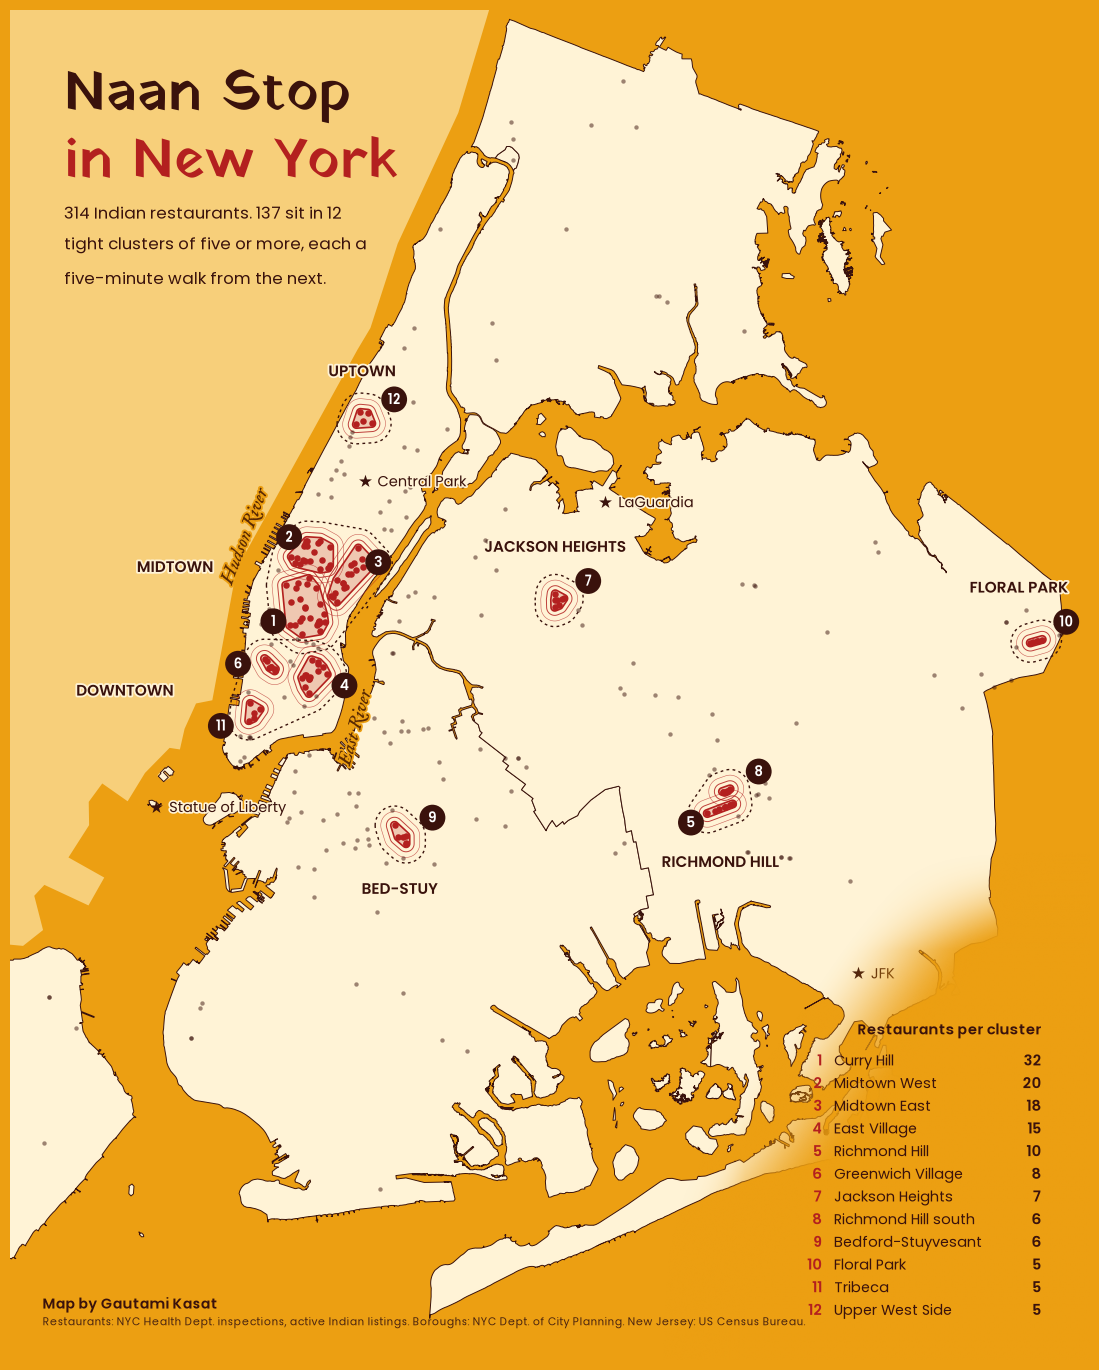

In [9]:
import matplotlib.patheffects as pe
SAFFRON, LAND, NJ, CHILI, INK = "#ec9f12", "#fff3d6", "#f7cf7a", "#b3201f", "#3a120c"
fig, ax = poster.page(SAFFRON)
food_m = food.to_crs(3857)
nj.to_crs(3857).plot(ax=ax, color=NJ, lw=0, zorder=0)
boroughs.to_crs(3857).plot(ax=ax, color=LAND, edgecolor=INK, lw=0.7, zorder=1)
ax.set_axis_off()
fx0, fy0, fx1, fy1 = poster.fit_frame(ax, -74.10, 40.53, -73.69, 40.918)
W = fx1 - fx0

# ripples around each cluster, thinning as they spread
ranked = list(sizes.index)
for c in ranked:
    pts = food_m[food_m.cluster == c]
    hull = pts.geometry.union_all().convex_hull
    for grow, lw, alpha in [(120, 1.2, 1), (260, 0.7, 0.85), (440, 0.4, 0.7)]:
        gpd.GeoSeries([hull.buffer(grow * 1.32)], crs=3857).plot(ax=ax, facecolor="none", edgecolor=CHILI, lw=lw, alpha=alpha, zorder=3)
    gpd.GeoSeries([hull.buffer(120 * 1.32)], crs=3857).plot(ax=ax, facecolor=CHILI, alpha=0.2, lw=0, zorder=2)
food_m[food_m.cluster < 0].plot(ax=ax, color=INK, markersize=10, alpha=0.5, lw=0, zorder=4)
food_m[food_m.cluster >= 0].plot(ax=ax, color=CHILI, markersize=22, lw=0, zorder=5)

# dashed outlines naming the bigger areas
by_name = {names[c]: c for c in ranked}
AREAS = {"MIDTOWN": (["Midtown West", "Midtown East", "Curry Hill"], (-0.135, 0.015)),
         "DOWNTOWN": (["East Village", "Greenwich Village", "Tribeca"], (-0.145, -0.005)),
         "UPTOWN": (["Upper West Side"], (0.0, 0.045)),
         "JACKSON HEIGHTS": (["Jackson Heights"], (0.0, 0.05)),
         "RICHMOND HILL": (["Richmond Hill", "Richmond Hill south"], (0.0, -0.055)),
         "BED-STUY": (["Bedford-Stuyvesant"], (0.0, -0.05)),
         "FLORAL PARK": (["Floral Park"], (-0.015, 0.05))}
for label, (members, (dx, dy)) in AREAS.items():
    pts = food_m[food_m.cluster.isin([by_name[n] for n in members])]
    shape = pts.geometry.union_all().convex_hull.buffer(620 * 1.32)
    gpd.GeoSeries([shape], crs=3857).plot(ax=ax, facecolor="none", edgecolor=INK, lw=1.0, linestyle=(0, (2, 2.4)), zorder=6)
    cx, cy = shape.centroid.coords[0]
    poster.halo_text(ax, cx + W * dx, cy + W * dy, label, color=INK, path=poster.POPPINS_BOLD, size=11, halo=LAND, halo_width=2.6, ha="center", va="center", zorder=9)

# a numbered marker on each cluster
OFFSET = {"Midtown West": (-0.02, 0.016), "Midtown East": (0.028, 0.014), "Curry Hill": (-0.034, -0.008), "East Village": (0.03, -0.01),
          "Greenwich Village": (-0.03, 0.002), "Tribeca": (-0.03, -0.012), "Richmond Hill south": (0.03, 0.018), "Richmond Hill": (-0.03, -0.014)}
for rank, c in enumerate(ranked, 1):
    cx, cy = food_m[food_m.cluster == c].geometry.union_all().centroid.coords[0]
    dx, dy = OFFSET.get(names[c], (0.028, 0.018))
    ax.text(cx + W * dx, cy + W * dy, str(rank), color="white", fontproperties=poster.font(poster.POPPINS_BOLD, 9.5), ha="center", va="center", zorder=8,
            bbox=dict(boxstyle="circle,pad=0.28", fc=INK, ec="none"))

# rivers, in italics on the water
def river(lon, lat, text, angle):
    x, y = poster.merc(lon, lat)
    t = ax.text(x, y, text, color="#5a2a03", fontproperties=poster.font(poster.OLD_ITALIC, 14), rotation=angle, ha="center", va="center", zorder=7)
    t.set_path_effects([pe.withStroke(linewidth=2.6, foreground=SAFFRON)])
river(-74.0105, 40.767, "Hudson River", 69)
river(-73.9685, 40.712, "East River", 74)

# landmarks for finding your way
LANDMARKS = {"Statue of Liberty": (-74.0445, 40.6892, "left"), "LaGuardia": (-73.8740, 40.7769, "left"), "JFK": (-73.7781, 40.6413, "left"), "Central Park": (-73.9654, 40.7829, "left")}
for name, (lon, lat, side) in LANDMARKS.items():
    x, y = poster.merc(lon, lat)
    ax.scatter([x], [y], marker="*", s=95, color=INK, lw=0, zorder=9)
    poster.halo_text(ax, x + W * 0.012, y, name, color=INK, path=poster.POPPINS, size=10.5, halo=LAND, halo_width=2.4, ha="left", va="center", zorder=9)
ax.set_xlim(fx0, fx1); ax.set_ylim(fy0, fy1)

fig.text(0.05, 0.968, "Naan Stop", color=INK, fontproperties=poster.font(poster.YATRA, 40), va="top")
fig.text(0.05, 0.918, "in New York", color=CHILI, fontproperties=poster.font(poster.YATRA, 40), va="top")
fig.text(0.05, 0.862, f"{len(food)} Indian restaurants. {in_clusters} sit in {len(sizes)}\ntight clusters of five or more, each a\nfive-minute walk from the next.", color=INK,
         fontproperties=poster.font(poster.POPPINS, 12), va="top", linespacing=1.4)

# the list melts into the corner: the water color fades in over the map, with no box
from matplotlib.colors import to_rgb
fade = fig.add_axes([0.6, 0, 0.4, 0.38], zorder=1)
fade.set_axis_off()
u, v = np.meshgrid(np.linspace(0, 1, 300), np.linspace(1, 0, 300))
reach = np.clip((u * 1.2 + (1 - v) * 1.0 - 0.7) / 0.42, 0, 1) * np.clip(u / 0.2, 0, 1) * np.clip((1 - v) / 0.2, 0, 1)
rgba = np.dstack([np.full(u.shape + (3,), to_rgb(SAFFRON)), reach * reach * (3 - 2 * reach)])
fade.imshow(rgba, extent=(0, 1, 0, 1), aspect="auto", interpolation="bilinear")

fig.text(0.955, 0.245, "Restaurants per cluster", color=INK, fontproperties=poster.font(poster.POPPINS_BOLD, 10.5), va="center", ha="right", zorder=21)
for i, c in enumerate(ranked):
    y = 0.222 - i * 0.0168
    fig.text(0.752, y, f"{i + 1}", color=CHILI, fontproperties=poster.font(poster.POPPINS_BOLD, 10.5), va="center", ha="right", zorder=21)
    fig.text(0.763, y, names[c], color=INK, fontproperties=poster.font(poster.POPPINS, 10.5), va="center", zorder=21)
    fig.text(0.955, y, f"{sizes[c]}", color=INK, fontproperties=poster.font(poster.POPPINS_BOLD, 10.5), va="center", ha="right", zorder=21)
poster.credit(fig, CREDITS, x=0.03, path=poster.POPPINS, name_path=poster.POPPINS_BOLD, color="#4a2410", name_color=INK, size=7.8)

## 5 · Export

In [10]:
publish.save(fig, day=DAY, slug=SLUG, prompt=PROMPT, title=TITLE.replace("\n", " "),
             subtitle=f"{len(food)} Indian restaurants, {len(sizes)} clusters", series="city", tool="Python",
             notebook=NOTEBOOK, credits=CREDITS)

map        output/day04_clusters-nyc-indian.png
thumbnail  png_thumbnail/day04_clusters-nyc-indian.png
caption    captions/day04_clusters-nyc-indian.md
live link  https://gautamik01.github.io/30-day-map-challenge-2026/output/day04_clusters-nyc-indian.png  (after you push)
